In [2]:
SID4 = 2733
SEED = 2733
SLICE = 733
HP_ID = 3
CLS_A = 3
CLS_B = 7

In [3]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 207kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.83MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.0MB/s]


In [4]:
class FCAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 32)
        )

        self.decoder = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        output = self.decoder(z)
        return output.view(-1, 1, 28, 28)

In [5]:
model = FCAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        reconstructed = model(images)
        loss = criterion(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss / len(train_loader):.4f}")

Epoch 1/10, Loss: 0.0363
Epoch 2/10, Loss: 0.0192
Epoch 3/10, Loss: 0.0166
Epoch 4/10, Loss: 0.0149
Epoch 5/10, Loss: 0.0138
Epoch 6/10, Loss: 0.0130
Epoch 7/10, Loss: 0.0124
Epoch 8/10, Loss: 0.0120
Epoch 9/10, Loss: 0.0116
Epoch 10/10, Loss: 0.0113


In [6]:
model.eval()
test_loss = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        reconstructed = model(images)
        test_loss += criterion(reconstructed, images).item()

test_loss /= len(test_loader)
print(f"Test Reconstruction MSE: {test_loss:.4f}")

Test Reconstruction MSE: 0.0114


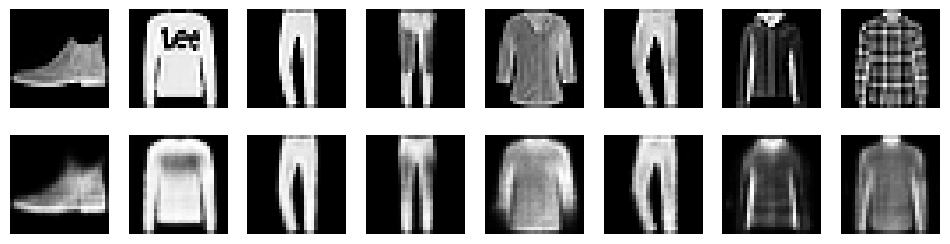

In [7]:
import matplotlib.pyplot as plt

model.eval()
images, _ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed = model(images)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))

for i in range(8):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
plt.show()

The FC-AE successfully reconstructed the general structure of FashionMNIST images. However, fine details were blurred, which is typical for autoencoders trained with MSE loss.

In [8]:
class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        output = self.decoder(z)
        return output.view(-1, 1, 28, 28), mu, logvar

In [9]:
class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        return mu + epsilon * std

    def forward(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        z = self.reparameterize(mu, logvar)
        output = self.decoder(z)
        return output.view(-1, 1, 28, 28), mu, logvar

In [10]:
def vae_loss(reconstructed, images, mu, logvar):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstructed, images, reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + kl_loss

In [11]:
vae_model = VAE().to(device)
optimizer = torch.optim.Adam(vae_model.parameters(), lr=1e-3)

epochs = 10

for epoch in range(epochs):
    vae_model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        reconstructed, mu, logvar = vae_model(images)
        loss = vae_loss(reconstructed, images, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_data)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

Epoch 1/10, Loss: 307.4015
Epoch 2/10, Loss: 268.0477
Epoch 3/10, Loss: 260.4526
Epoch 4/10, Loss: 255.7675
Epoch 5/10, Loss: 252.5604
Epoch 6/10, Loss: 250.3013
Epoch 7/10, Loss: 248.7154
Epoch 8/10, Loss: 247.7086
Epoch 9/10, Loss: 246.8826
Epoch 10/10, Loss: 246.3015


In [12]:
vae_model.eval()
test_loss = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        reconstructed, mu, logvar = vae_model(images)
        test_loss += vae_loss(
            reconstructed, images, mu, logvar
        ).item()

test_loss /= len(test_data)

print(f"VAE Test Loss: {test_loss:.4f}")

VAE Test Loss: 248.0277


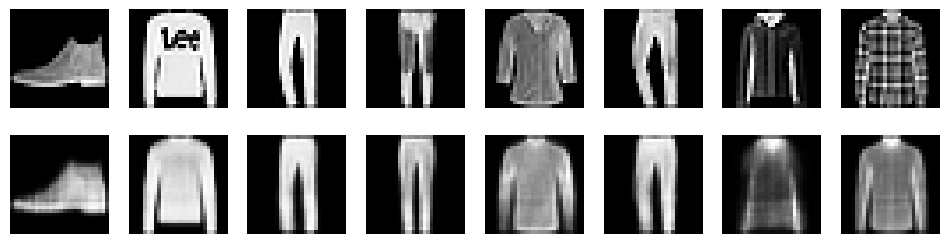

In [13]:
vae_model.eval()
images, _ = next(iter(test_loader))
images = images.to(device)

with torch.no_grad():
    reconstructed, _, _ = vae_model(images)

fig, axes = plt.subplots(2, 8, figsize=(12, 3))

for i in range(8):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")
plt.show()

The VAE preserved the main clothing shapes but produced smoother, blurrier images due to KL-divergence regularization.